In [ ]:

!pip -q install datasets


In [ ]:

from datasets import load_dataset

dataset = load_dataset(
    "electricsheepafrica/africa-fewsnet-staple-food-price-data-for-zimbabwe-monthly-4566"
)

print(dataset)


README.md:   0%|          | 0.00/6.13k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 54.7kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.6kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3902 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/976 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['country', 'market', 'admin_1', 'longitude', 'latitude', 'cpcv2', 'product', 'source_document', 'period_date', 'price_type', 'product_source', 'unit', 'unit_type', 'currency', 'value', 'esa_source', 'esa_processed'],
        num_rows: 3902
    })
    test: Dataset({
        features: ['country', 'market', 'admin_1', 'longitude', 'latitude', 'cpcv2', 'product', 'source_document', 'period_date', 'price_type', 'product_source', 'unit', 'unit_type', 'currency', 'value', 'esa_source', 'esa_processed'],
        num_rows: 976
    })
})


In [ ]:

import pandas as pd

# Combine the downloaded training and testing records for inspection
df = pd.concat(
    [dataset["train"].to_pandas(),
     dataset["test"].to_pandas()],
    ignore_index=True
)

# Display the first five records
print("Dataset shape:", df.shape)
display(df.head())

# List the available food products
print("\nProducts available:")
print(sorted(df["product"].dropna().unique()))

# Check which currencies are present
print("\nCurrencies available:")
print(df["currency"].value_counts(dropna=False))


Dataset shape: (4878, 17)


,country,market,admin_1,longitude,latitude,cpcv2,product,source_document,period_date,price_type,product_source,unit,unit_type,currency,value,esa_source,esa_processed
0,Zimbabwe,"Harare, Mbare",Harare,31.0312,-17.8680,P23520AA,Refined sugar,Famine Early Warning Systems Network (FEWS NET...,2016-12-31,Retail,Local,kg,Weight,ZWL,NaN,HDX,2026-04-05
1,Zimbabwe,"Masvingo, Mucheke",Masvingo,30.8169,-20.0793,P33360AA,Diesel,Famine Early Warning Systems Network (FEWS NET...,2022-03-31,Retail,Local,L,Volume,ZWL,213.90,HDX,2026-04-05
2,Zimbabwe,"Harare, Mbare",Harare,31.0312,-17.8680,P23490AA,Bread,Famine Early Warning Systems Network (FEWS NET...,2011-09-30,Retail,Local,700_g,Weight,USD,0.50,HDX,2026-04-05
3,Zimbabwe,"Gweru, Kombayi",Midlands,29.8177,-19.4513,P33360AA,Diesel,Famine Early Warning Systems Network (FEWS NET...,2012-07-31,Retail,Local,L,Volume,ZWL,1.30,HDX,2026-04-05
4,Zimbabwe,"Masvingo, Mucheke",Masvingo,30.8169,-20.0793,P33360AA,Diesel,Famine Early Warning Systems Network (FEWS NET...,2019-05-31,Retail,Local,L,Volume,ZWL,3.41,HDX,2026-04-05



Products available:
['Beef (Fresh bovine meat)', 'Bread', 'Diesel', 'Gasoline', 'Maize Grain (White)', 'Refined Vegetable Oil', 'Refined sugar', 'Roller Maize Meal', 'Soap', 'Sorghum', 'Tea leaves (Mixed)', 'Wheat Flour']

Currencies available:
currency
ZWL    2707
USD    2171
Name: count, dtype: int64


In [ ]:

# Check the number of records for each product
print("Records per product:")
print(df["product"].value_counts().to_string())

# Examine currencies, units and missing prices for Roller Maize Meal
maize = df[df["product"] == "Roller Maize Meal"].copy()

print("\nRoller Maize Meal records:", len(maize))

print("\nRecords by currency:")
print(maize["currency"].value_counts(dropna=False).to_string())

print("\nRecords by unit:")
print(maize["unit"].value_counts(dropna=False).to_string())

print("\nMissing prices:")
print(maize["value"].isna().sum())

print("\nDate range:")
print(maize["period_date"].min(), "to", maize["period_date"].max())


Records per product:
product
Diesel                      1298
Gasoline                    1298
Bread                        396
Refined sugar                396
Refined Vegetable Oil        396
Roller Maize Meal            396
Maize Grain (White)          396
Soap                          64
Wheat Flour                   64
Tea leaves (Mixed)            64
Beef (Fresh bovine meat)      64
Sorghum                       46

Roller Maize Meal records: 396

Records by currency:
currency
ZWL    217
USD    179

Records by unit:
unit
kg    396

Missing prices:
23

Date range:
2004-04-30 00:00:00 to 2022-04-30 00:00:00


In [ ]:

# Convert the date column to proper datetime format
maize["period_date"] = pd.to_datetime(maize["period_date"])

# Remove records with missing prices for this inspection
maize_valid = maize.dropna(subset=["value"]).copy()

print("Records with valid prices:", len(maize_valid))

print("\nValid records by currency:")
print(maize_valid["currency"].value_counts().to_string())

print("\nPrice summary by currency:")
print(
    maize_valid.groupby("currency")["value"]
    .agg(["count", "min", "median", "max", "mean"])
    .round(2)
)

print("\nRecords by year and currency:")
maize_valid["year"] = maize_valid["period_date"].dt.year
print(
    maize_valid.groupby(["currency", "year"])
    .size()
    .to_string()
)


Records with valid prices: 373

Valid records by currency:
currency
ZWL    204
USD    169

Price summary by currency:
          count   min  median     max  mean
currency                                   
USD         169  0.02    0.47    0.96  0.43
ZWL         204  0.02    0.50  160.00  7.55

Records by year and currency:
currency  year
USD       2004     8
          2005    10
          2006    10
          2007    12
          2008     7
          2009    12
          2010    12
          2011    12
          2012    12
          2013    12
          2014    12
          2015    12
          2016    12
          2017    12
          2018    12
          2019     2
ZWL       2004     8
          2005    10
          2006    10
          2007    12
          2008     7
          2009    12
          2010    12
          2011    12
          2012    12
          2013    12
          2014    12
          2015    12
          2016    12
          2017    12
          2018    12
         

Valid USD records: 169
Missing prices: 0
Date range: 2004-04-30 00:00:00 to 2019-02-28 00:00:00


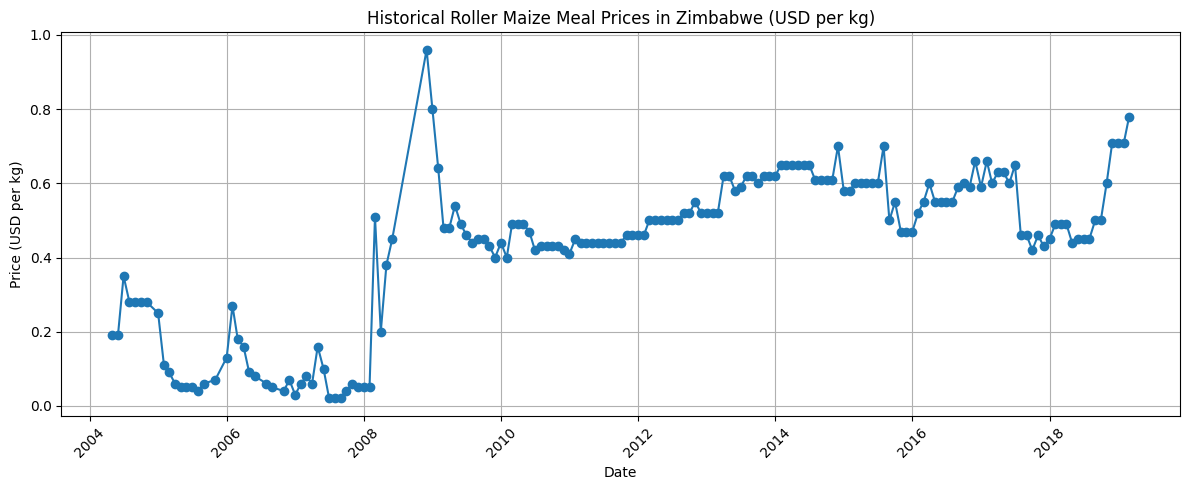

In [ ]:

import matplotlib.pyplot as plt

# Keep only Roller Maize Meal prices recorded in USD
usd_maize = maize_valid[
    maize_valid["currency"] == "USD"
].copy()

# Sort observations by date
usd_maize = usd_maize.sort_values("period_date")

print("Valid USD records:", len(usd_maize))
print("Missing prices:", usd_maize["value"].isna().sum())
print("Date range:",
      usd_maize["period_date"].min(),
      "to",
      usd_maize["period_date"].max())

# Plot the historical prices
plt.figure(figsize=(12, 5))
plt.plot(
    usd_maize["period_date"],
    usd_maize["value"],
    marker="o"
)
plt.title("Historical Roller Maize Meal Prices in Zimbabwe (USD per kg)")
plt.xlabel("Date")
plt.ylabel("Price (USD per kg)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


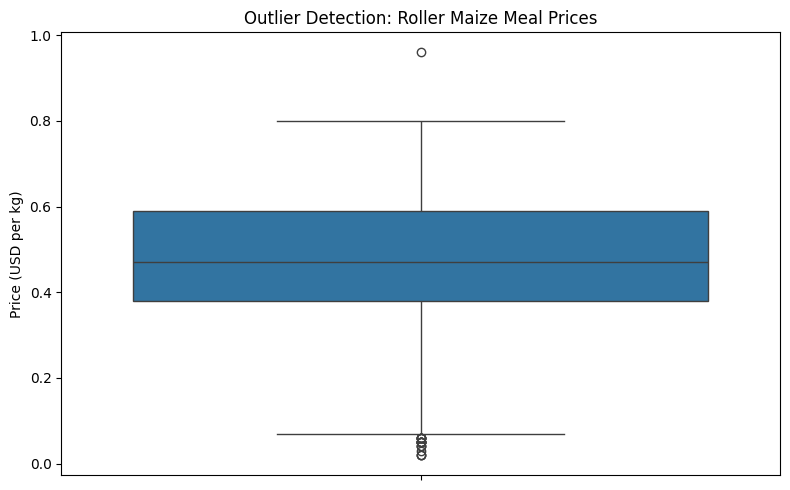

First quartile (Q1): 0.38
Third quartile (Q3): 0.59
Lower outlier boundary: 0.065
Upper outlier boundary: 0.905
Potential outliers found: 21


,period_date,value,currency
770,2005-03-31,0.06,USD
4676,2005-04-30,0.05,USD
1689,2005-05-31,0.05,USD
4426,2005-06-30,0.05,USD
2119,2005-07-31,0.04,USD
4440,2005-08-31,0.06,USD
32,2006-07-31,0.06,USD
3373,2006-08-31,0.05,USD
1348,2006-10-31,0.04,USD
1571,2006-12-31,0.03,USD


In [ ]:

# Check for potential outliers in USD maize meal prices

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.boxplot(y=usd_maize["value"])

plt.title("Outlier Detection: Roller Maize Meal Prices")
plt.ylabel("Price (USD per kg)")
plt.tight_layout()
plt.show()

# Calculate the interquartile range (IQR)
Q1 = usd_maize["value"].quantile(0.25)
Q3 = usd_maize["value"].quantile(0.75)
IQR = Q3 - Q1

# Identify potential outliers using the 1.5 × IQR rule
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = usd_maize[
    (usd_maize["value"] < lower_bound) |
    (usd_maize["value"] > upper_bound)
]

print("First quartile (Q1):", round(Q1, 4))
print("Third quartile (Q3):", round(Q3, 4))
print("Lower outlier boundary:", round(lower_bound, 4))
print("Upper outlier boundary:", round(upper_bound, 4))
print("Potential outliers found:", len(outliers))

display(outliers[["period_date", "value", "currency"]])


### Outlier Detection and Analysis

Potential outliers were identified using the Interquartile Range (IQR) method. The first quartile (Q1) was USD 0.38 per kg, while the third quartile (Q3) was USD 0.59 per kg. The calculated lower and upper boundaries were USD 0.065 and USD 0.905 per kg, respectively.

A total of 21 observations fell outside these boundaries. Most were relatively low prices recorded between 2005 and 2008, while one unusually high observation of USD 0.96 per kg occurred in November 2008. These values were retained because an unusual price does not necessarily indicate an error. Removing genuine historical prices could distort the analysis and reduce the representativeness of the dataset.

In [ ]:

# Create time-based features for the prediction models
model_data = usd_maize[
    ["period_date", "value"]
].copy()

model_data["year"] = model_data["period_date"].dt.year
model_data["month"] = model_data["period_date"].dt.month

# Sort records chronologically
model_data = model_data.sort_values("period_date").reset_index(drop=True)

# Display the prepared data
print("Number of observations:", len(model_data))
print("\nFirst five observations:")
display(model_data.head())

print("\nLast five observations:")
display(model_data.tail())

print("\nMissing values:")
print(model_data.isna().sum())


Number of observations: 169

First five observations:


,period_date,value,year,month
0,2004-04-30,0.19,2004,4
1,2004-05-31,0.19,2004,5
2,2004-06-30,0.35,2004,6
3,2004-07-31,0.28,2004,7
4,2004-08-31,0.28,2004,8



Last five observations:


,period_date,value,year,month
164,2018-10-31,0.60,2018,10
165,2018-11-30,0.71,2018,11
166,2018-12-31,0.71,2018,12
167,2019-01-31,0.71,2019,1
168,2019-02-28,0.78,2019,2



Missing values:
period_date    0
value          0
year           0
month          0
dtype: int64


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Ensure observations are ordered by date
model_data = model_data.sort_values("period_date").reset_index(drop=True)

# Features used to predict the price
X = model_data[["year", "month"]]
y = model_data["value"]

# Use earlier records for training and later records for testing
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# Model 1: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

# Model 2: Random Forest Regression
forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

# Evaluate both models
def evaluate_model(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Random Forest", y_test, forest_predictions)
])

print("\nModel evaluation results:")
display(results.round(4))


Training observations: 135
Testing observations: 34

Model evaluation results:


,Model,MAE,RMSE,R2
0,Linear Regression,0.1967,0.2223,-4.3522
1,Random Forest,0.0944,0.1108,-0.3312


In [ ]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Prepare the USD prices in chronological order
improved_data = usd_maize[
    ["period_date", "value"]
].copy()

improved_data = improved_data.sort_values("period_date").reset_index(drop=True)

improved_data["year"] = improved_data["period_date"].dt.year
improved_data["month"] = improved_data["period_date"].dt.month

# Add historical price features
improved_data["price_previous_month"] = improved_data["value"].shift(1)
improved_data["price_three_months_ago"] = improved_data["value"].shift(3)

# Remove rows that lack the historical prices needed for these features
improved_data = improved_data.dropna().reset_index(drop=True)

# Define features and target
features = [
    "year",
    "month",
    "price_previous_month",
    "price_three_months_ago"
]

X = improved_data[features]
y = improved_data["value"]

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(improved_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Usable observations:", len(improved_data))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# Train Linear Regression
improved_linear = LinearRegression()
improved_linear.fit(X_train, y_train)
pred_linear = improved_linear.predict(X_test)

# Train Random Forest
improved_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)
improved_forest.fit(X_train, y_train)
pred_forest = improved_forest.predict(X_test)

# Simple baseline: predict using the previous month's actual price
pred_baseline = X_test["price_previous_month"].to_numpy()

# Compare all three approaches
def evaluate(name, actual, predicted):
    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

comparison = pd.DataFrame([
    evaluate("Previous-month baseline", y_test, pred_baseline),
    evaluate("Linear Regression with lags", y_test, pred_linear),
    evaluate("Random Forest with lags", y_test, pred_forest)
])

display(comparison.round(4))


Usable observations: 166
Training observations: 132
Testing observations: 34


,Model,MAE,RMSE,R2
0,Previous-month baseline,0.0350,0.0539,0.6855
1,Linear Regression with lags,0.0549,0.0675,0.5071
2,Random Forest with lags,0.0455,0.0678,0.5013


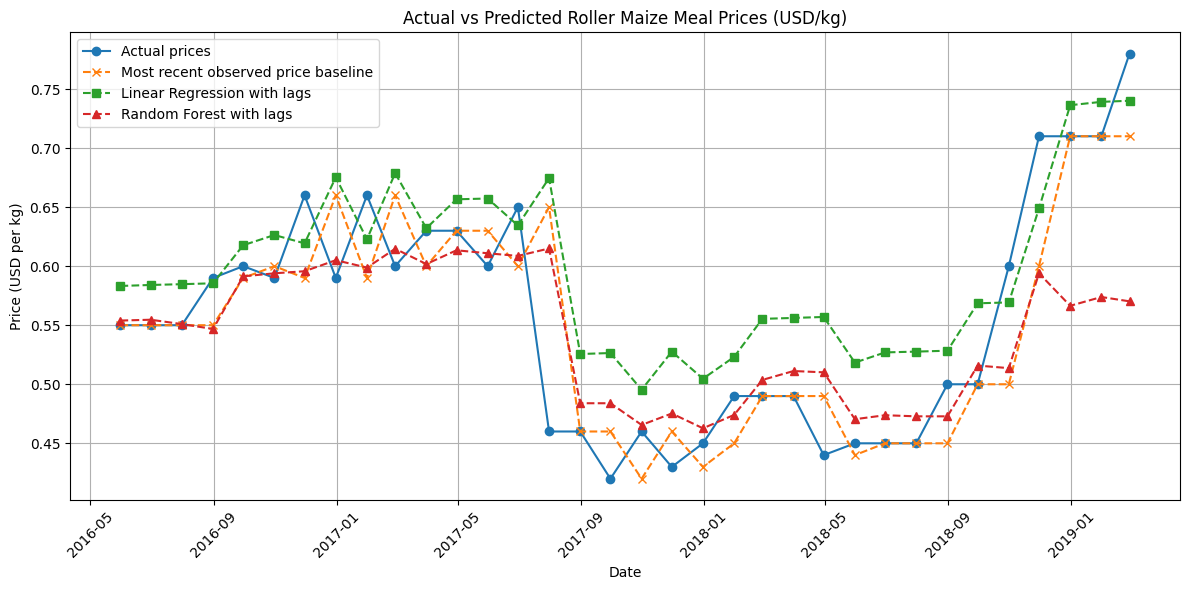

In [ ]:

import matplotlib.pyplot as plt

# Compare actual prices with predictions on the test period
test_dates = improved_data["period_date"].iloc[split_index:]

plt.figure(figsize=(12, 6))

plt.plot(
    test_dates, y_test,
    marker="o", label="Actual prices"
)
plt.plot(
    test_dates, pred_baseline,
    marker="x", linestyle="--",
    label="Most recent observed price baseline"
)
plt.plot(
    test_dates, pred_linear,
    marker="s", linestyle="--",
    label="Linear Regression with lags"
)
plt.plot(
    test_dates, pred_forest,
    marker="^", linestyle="--",
    label="Random Forest with lags"
)

plt.title("Actual vs Predicted Roller Maize Meal Prices (USD/kg)")
plt.xlabel("Date")
plt.ylabel("Price (USD per kg)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


**Interpretation of the Actual vs Predicted Prices Graph**

The graph compares the actual Roller Maize Meal prices with predictions from the previous-observation baseline, Linear Regression and Random Forest Regression. The actual prices show the observed market values, while the other lines show each approach's estimates for the same test period. Predictions that remain closer to the actual-price line indicate smaller prediction errors. The graph complements the numerical evaluation metrics and helps identify periods when the models underpredict or overpredict prices.

In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Keep the chronological order of observations
tuning_data = improved_data.sort_values("period_date").reset_index(drop=True)

features = [
    "year",
    "month",
    "price_previous_month",
    "price_three_months_ago"
]

X = tuning_data[features]
y = tuning_data["value"]

# Reserve the latest 20% for final testing
split_index = int(len(tuning_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Use the last part of the training data to compare settings
validation_index = int(len(X_train) * 0.8)

X_fit = X_train.iloc[:validation_index]
y_fit = y_train.iloc[:validation_index]

X_val = X_train.iloc[validation_index:]
y_val = y_train.iloc[validation_index:]

# Try several Random Forest settings
settings = [
    {"n_estimators": 100, "max_depth": 3},
    {"n_estimators": 100, "max_depth": 5},
    {"n_estimators": 200, "max_depth": 3},
    {"n_estimators": 200, "max_depth": 5},
    {"n_estimators": 200, "max_depth": None}
]

tuning_results = []

for setting in settings:
    model = RandomForestRegressor(
        **setting,
        random_state=42
    )
    model.fit(X_fit, y_fit)
    predictions = model.predict(X_val)

    tuning_results.append({
        "Trees": setting["n_estimators"],
        "Maximum depth": str(setting["max_depth"]),
        "Validation MAE": mean_absolute_error(y_val, predictions),
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_val, predictions)
        )
    })

tuning_results = pd.DataFrame(tuning_results)
display(tuning_results.round(4))

print("Validation observations:", len(X_val))
print("Final test observations reserved:", len(X_test))



,Trees,Maximum depth,Validation MAE,Validation RMSE
0,100,3,0.0396,0.0498
1,100,5,0.0352,0.0456
2,200,3,0.0404,0.0503
3,200,5,0.0354,0.0454
4,200,None,0.0365,0.0475


Validation observations: 27
Final test observations reserved: 34


In [ ]:

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Test Linear Regression and Ridge Regression with different regularisation strengths
alphas = [0.01, 0.1, 1, 10, 100]

linear_tuning_results = []

# Ordinary Linear Regression
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)
linear_model.fit(X_fit, y_fit)
linear_predictions = linear_model.predict(X_val)

linear_tuning_results.append({
    "Model": "Linear Regression",
    "Alpha": "Not applicable",
    "Validation MAE": mean_absolute_error(y_val, linear_predictions),
    "Validation RMSE": np.sqrt(mean_squared_error(y_val, linear_predictions))
})

# Ridge Regression: test different alpha values
for alpha in alphas:
    ridge_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )
    ridge_model.fit(X_fit, y_fit)
    ridge_predictions = ridge_model.predict(X_val)

    linear_tuning_results.append({
        "Model": "Ridge Regression",
        "Alpha": alpha,
        "Validation MAE": mean_absolute_error(y_val, ridge_predictions),
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_val, ridge_predictions)
        )
    })

linear_tuning_results = pd.DataFrame(linear_tuning_results)
display(linear_tuning_results.round(4))

best_ridge_row = linear_tuning_results[
    linear_tuning_results["Model"] == "Ridge Regression"
].sort_values("Validation MAE").iloc[0]

print("Best Ridge alpha:", best_ridge_row["Alpha"])
print("Best Ridge validation MAE:", round(best_ridge_row["Validation MAE"], 4))


,Model,Alpha,Validation MAE,Validation RMSE
0,Linear Regression,Not applicable,0.0472,0.0678
1,Ridge Regression,0.01,0.0472,0.0678
2,Ridge Regression,0.1,0.0472,0.0678
3,Ridge Regression,1,0.0474,0.0678
4,Ridge Regression,10,0.0470,0.0666
5,Ridge Regression,100,0.0486,0.0606


Best Ridge alpha: 10
Best Ridge validation MAE: 0.047


In [ ]:

# Train the selected Random Forest using all training observations
final_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

final_forest.fit(X_train, y_train)

# Predict prices in the reserved test period
final_forest_predictions = final_forest.predict(X_test)

# Compare the tuned model against the baseline
final_results = pd.DataFrame([
    {
        "Model": "Previous-month baseline",
        "MAE": mean_absolute_error(
            y_test, X_test["price_previous_month"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, X_test["price_previous_month"]
        )),
        "R2": r2_score(
            y_test, X_test["price_previous_month"]
        )
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": mean_absolute_error(
            y_test, final_forest_predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_test, final_forest_predictions
        )),
        "R2": r2_score(
            y_test, final_forest_predictions
        )
    }
])

print("Final evaluation on reserved test data:")
display(final_results.round(4))


Final evaluation on reserved test data:


,Model,MAE,RMSE,R2
0,Previous-month baseline,0.0350,0.0539,0.6855
1,Tuned Random Forest,0.0455,0.0678,0.5013


In [ ]:

# Simple prediction demonstration using the trained Random Forest

def predict_maize_price(year, month, previous_price, price_three_months_ago):
    input_data = pd.DataFrame([{
        "year": year,
        "month": month,
        "price_previous_month": previous_price,
        "price_three_months_ago": price_three_months_ago
    }])

    predicted_price = final_forest.predict(input_data)[0]
    baseline_price = previous_price

    print(f"Random Forest estimated price: ${predicted_price:.2f} per kg")
    print(f"Previous-price baseline:       ${baseline_price:.2f} per kg")
    print("Currency: USD")
    print("Note: This is a historical-data prototype, not a current market quote.")

# Example demonstration using illustrative input values
predict_maize_price(
    year=2018,
    month=12,
    previous_price=0.71,
    price_three_months_ago=0.60
)


Random Forest estimated price: $0.57 per kg
Previous-price baseline:       $0.71 per kg
Currency: USD
Note: This is a historical-data prototype, not a current market quote.


In [ ]:
# Check whether the trained Random Forest model is available
if "final_forest" in globals():
    print("SUCCESS: Your trained Random Forest model is available.")
else:
    print("The model is not currently loaded. Run the earlier training cells first.")

SUCCESS: Your trained Random Forest model is available.


In [ ]:
%pip install -q gradio

In [ ]:
import gradio as gr

print("SUCCESS: Gradio is ready.")
print("Gradio version:", gr.__version__)

SUCCESS: Gradio is ready.
Gradio version: 6.30.0


In [ ]:

import gradio as gr
import pandas as pd

def predict_maize_price_frontend(
    year,
    month,
    previous_price,
    price_three_months_ago,
    quantity_kg
):
    # Validate the inputs
    if previous_price < 0 or price_three_months_ago < 0:
        raise gr.Error("Prices must be zero or greater.")

    if quantity_kg <= 0:
        raise gr.Error("Quantity must be greater than zero.")

    # Prepare the input for the trained Random Forest model
    input_data = pd.DataFrame([{
        "year": int(year),
        "month": int(month),
        "price_previous_month": float(previous_price),
        "price_three_months_ago": float(price_three_months_ago)
    }])

    # Predict the price per kilogram
    predicted_price = float(final_forest.predict(input_data)[0])

    # Calculate total costs for the selected quantity
    predicted_total = predicted_price * float(quantity_kg)
    baseline_total = float(previous_price) * float(quantity_kg)

    return (
        f"Random Forest estimated price per kg: US${predicted_price:.2f}\n"
        f"Quantity requested: {float(quantity_kg):g} kg\n"
        f"Estimated total for {float(quantity_kg):g} kg: "
        f"US${predicted_total:.2f}\n\n"
        f"Previous-price baseline per kg: US${float(previous_price):.2f}\n"
        f"Baseline total for {float(quantity_kg):g} kg: "
        f"US${baseline_total:.2f}\n\n"
        "Currency: USD\n"
        "Note: Historical-data demonstration, not a current market quote. "
        "The selected USD dataset ends in February 2019."
    )

demo = gr.Interface(
    fn=predict_maize_price_frontend,
    inputs=[
        gr.Number(label="Year", value=2018, precision=0),
        gr.Dropdown(
            choices=list(range(1, 13)),
            value=12,
            label="Month (1 = January, 12 = December)"
        ),
        gr.Number(
            label="Previous available price (USD/kg)",
            value=0.71
        ),
        gr.Number(
            label="Price three observations earlier (USD/kg)",
            value=0.60
        ),
        gr.Number(
            label="Quantity of maize meal (kg)",
            value=10,
            minimum=0.01
        )
    ],
    outputs=gr.Textbox(label="Prediction Results", lines=8),
    title="Zimbabwe Roller Maize Meal Price Estimator",
    description=(
        "Predict a historical price per kilogram and calculate the "
        "estimated total for your chosen quantity."
    )
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f8894288d67e23ed57.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 1. Project Overview

**Project title:** Predicting Food Commodity Prices in Zimbabwe Using Machine Learning Techniques

This project investigates the use of machine learning regression techniques to estimate historical prices of Roller Maize Meal in Zimbabwe. The project uses historical commodity-price observations from the FEWS NET staple food price dataset for Zimbabwe, accessed through the Hugging Face dataset repository.

The selected records cover April 2004 to February 2019 and contain prices denominated in United States dollars (USD) per kilogram. The target variable is the recorded commodity price, while the explanatory features include the year, month, and previous observed prices.

## 2. Machine Learning Type

This is a **supervised machine learning regression** task. Supervised learning uses examples with known target values to train a model. Regression is appropriate because the target is a numerical price rather than a category.

Two regression algorithms were evaluated: Linear Regression and Random Forest Regression. A previous-observation baseline was also included to determine whether the machine learning models improved on a simple alternative.

## 3. Data Preparation

The dataset contains 4,878 records and 17 columns. Roller Maize Meal had 396 records, of which 373 contained valid prices. These valid records included 169 USD prices and 204 Zimbabwe-dollar prices.

To avoid combining values denominated in different currencies, the modelling experiment used the USD records only. This produced 169 observations with no missing values in the selected date and price fields. The observations were sorted chronologically. Year and month features were created, along with the previous available price and the price three observations earlier. Missing rows created by lag-feature construction were removed, leaving 166 observations for the improved experiment.

The data was split chronologically: earlier observations were used for model training and later observations were reserved for evaluation. This approach respects the time order of the data.

## 4. Model Evaluation

Model performance was assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²). Lower MAE and RMSE indicate smaller prediction errors, while higher R² indicates better performance relative to predicting the mean of the target values.

In the initial comparison, Random Forest outperformed Linear Regression on the test set, but both models had negative R² values. After adding lagged prices, the previous-observation baseline achieved MAE of 0.0350, RMSE of 0.0539, and R² of 0.6855. Linear Regression with lagged features achieved MAE of 0.0549, RMSE of 0.0675, and R² of 0.5071. Random Forest with lagged features achieved MAE of 0.0455, RMSE of 0.0678, and R² of 0.5013.

Random Forest was tuned using a validation subset. The selected configuration used 100 trees and a maximum depth of 5. On the reserved test set, this tuned model achieved the same results as the lagged-feature Random Forest comparison: MAE 0.0455, RMSE 0.0678, and R² 0.5013. The previous-observation baseline remained more accurate on these test observations.

## 5. Limitations and Ethical Considerations

The selected dataset is historical and ends in February 2019 for the USD Roller Maize Meal observations used in this experiment. Therefore, the model must not be presented as a reliable estimate of current market prices. Currency changes, inflation, transport costs, weather, supply disruptions, and other economic conditions can affect food prices but are not fully represented by the selected features.

The modelling dataset is small, and missing months mean that a previous observation does not always represent the immediately preceding calendar month. The results should therefore be interpreted as a limited historical experiment rather than a complete forecasting service.

The data contains market-price information rather than personal customer records, reducing direct personal-privacy risks. Nevertheless, the source should be attributed, the dataset's licence respected, and the model's limitations communicated clearly to avoid misleading users.

## 6. Dataset Source and Attribution

**Dataset title:** Africa FEWS NET Staple Food Price Data for Zimbabwe — Monthly

**Dataset repository:** Hugging Face

**Dataset URL:** https://huggingface.co/datasets/electricsheepafrica/africa-fewsnet-staple-food-price-data-for-zimbabwe-monthly-4566

**Original data source:** Famine Early Warning Systems Network (FEWS NET), distributed through the Humanitarian Data Exchange (HDX).

**Licence indicated by the repository:** Creative Commons Attribution 4.0 International (CC BY 4.0). The licence and attribution requirements should be checked against the repository's current dataset card before redistribution.

The dataset contains historical market-level commodity-price records for Zimbabwe. Relevant fields include market, product, observation date, currency, unit and recorded price. This project uses the Roller Maize Meal records denominated in USD per kilogram.

The dataset was loaded programmatically using the Hugging Face `datasets` library. The training and testing partitions were combined for exploratory inspection, after which the selected commodity and currency records were filtered and sorted by date. The final modelling evaluation used chronological training, validation and test partitions.

The dataset should be cited in the final report, and its original source and repository should be acknowledged in any public presentation or code repository.

## 7. Exploratory Data Analysis

Exploratory Data Analysis (EDA) was conducted to understand the dataset before model development. The initial inspection identified 4,878 records and 17 columns, including product, market, date, currency, unit and price.

The dataset contained 12 product categories. Roller Maize Meal was selected as the focus commodity because it is a relevant staple food for Zimbabwe. It had 396 records, including 373 valid price observations. The valid observations comprised 169 USD prices and 204 Zimbabwe-dollar prices.

The USD records were selected to avoid directly mixing prices denominated in different currencies. The selected records covered April 2004 to February 2019, with all recorded units expressed in kilograms. The data preparation stage identified 23 missing prices across the original Roller Maize Meal records; these records were excluded from the USD modelling subset because the selected USD observations contained no missing target prices.

A historical price graph was generated to inspect price movements over time. The graph and summary statistics were used to explore variation in recorded prices and identify potential limitations in the data.

The analysis is limited by the historical period, the relatively small number of USD observations, and gaps in the monthly records. These limitations influence the model's ability to generalise to other periods and current market conditions.

## 8. Feature Engineering

Feature engineering is the process of creating or selecting input variables that help a machine learning model learn patterns in the data.

The original price records included the observation date and the recorded price. The date was converted to a datetime format, and two calendar features, year and month, were extracted. These features allow the models to represent broad time-related patterns.

Two lagged price features were also created:

- **Previous available price:** the price in the preceding observation.
- **Price three observations earlier:** the price recorded three rows before the current observation.

Lagged features were created using the `shift()` operation after sorting the records chronologically. The first three observations lacked the required historical values and were removed, reducing the modelling dataset from 169 to 166 observations.

The previous available price is not always the immediately preceding calendar month's price because the dataset contains gaps. This distinction is important when interpreting the results.



## 9. Model Development and Hyperparameter Tuning

Three approaches were compared: a previous-observation baseline, Linear Regression, and Random Forest Regression. Ridge Regression was also evaluated as a regularised variant of Linear Regression.

Linear Regression models the relationship between input features and the numerical target. Ridge Regression adds a regularisation penalty to help control model coefficients. StandardScaler was used in a pipeline for the Linear Regression and Ridge Regression comparison, with scaling fitted on the training portion of the data. Random Forest Regression combines predictions from multiple decision trees and can represent nonlinear relationships.

The initial experiment used year and month as input features. Both machine learning models were evaluated on the final 34 observations, while earlier observations were used for training. The initial Random Forest performed better than Linear Regression on the test set, but both models had negative R² values.

The feature set was then expanded to include the previous available price and the price three observations earlier. This improved the evaluation results. The previous-observation baseline achieved the strongest performance among the three approaches in the final test comparison, showing that the most recent available price was a useful reference for the selected test period.

Random Forest hyperparameters were compared using a validation subset drawn from the training period. The tested configurations varied the number of trees and maximum tree depth. The configuration with 100 trees and a maximum depth of 5 was selected because it had the lowest validation MAE among the tested settings.

A further experiment compared ordinary Linear Regression with Ridge Regression using alpha values of 0.01, 0.1, 1, 10 and 100. Among the tested Ridge configurations, alpha = 10 achieved the lowest validation MAE of 0.0470. Alpha = 100 achieved the lowest validation RMSE of 0.0606. Ridge Regression was therefore selected by the MAE criterion for further consideration.

The selected Random Forest was retrained on the training partition and evaluated on the reserved test partition. Its performance did not surpass the previous-observation baseline. This outcome is reported as an experimental finding rather than hidden or presented as a successful improvement. The Ridge validation results are kept separate from the final test results to avoid treating validation performance as final test performance.

## 10. Prototype Demonstration

A prototype was developed using Gradio to provide a simple interface for estimating historical Roller Maize Meal prices. The interface accepts the year, month, previous available price, price three observations earlier, and the quantity required in kilograms.

The system passes the numerical input features to the trained Random Forest regression model to produce an estimated price per kilogram. It also calculates the estimated total cost by multiplying the predicted unit price by the requested quantity. A previous-price baseline estimate and its corresponding total cost are displayed for comparison.

The prototype demonstrates how a trained regression model can be integrated into a user-facing application. However, it is an experimental demonstration rather than a validated service for current market prices. The underlying USD price series ends in February 2019, and the test results show that the previous-price baseline outperformed the machine learning models. Consequently, the predictions should not be interpreted as current market quotations or relied upon for financial decisions.

## 11. Conclusion and Recommendations

This project investigated whether machine learning regression techniques could estimate historical Roller Maize Meal prices in Zimbabwe using market-price records denominated in USD per kilogram.

The experiment demonstrated a complete basic machine learning workflow: dataset loading, exploratory analysis, data filtering, missing-value inspection, chronological sorting, feature engineering, model training, hyperparameter tuning, evaluation and a prediction demonstration.

The results showed that the Random Forest model with lagged features performed better than Linear Regression on MAE, but the previous-observation baseline outperformed both machine learning models on the reserved test set. The baseline achieved MAE of 0.0350, RMSE of 0.0539 and R² of 0.6855. The tuned Random Forest achieved MAE of 0.0455, RMSE of 0.0678 and R² of 0.5013.

These results suggest that recent price history was a strong predictor for the selected observations. However, the dataset is relatively small and historical, and the selected USD series ends in February 2019. Consequently, the model should not be used to claim accurate predictions of current Zimbabwean food prices.

Future work should investigate newer data, additional market and economic variables, alternative forecasting approaches, and more extensive chronological validation. A larger dataset could help determine whether machine learning models can provide consistent improvements over simple baseline methods.

Overall, the project demonstrates how machine learning can be applied to a Zimbabwean food-price problem while also showing why careful evaluation, transparent reporting and recognition of limitations are essential.